# Notebook 01 — Data Inventory

## Mục tiêu

Kiểm kê cấu trúc và số lượng dữ liệu CBIS-DDSM, khảo sát metadata và kiểm tra khả năng đọc DICOM header.

## Phạm vi

1. Xác nhận đường dẫn và các tệp dữ liệu đầu vào.
2. Khảo sát cấu trúc các CSV mô tả tổn thương và `metadata.csv`.
3. Kiểm kê ảnh DICOM và kiểm tra header.
4. Đối chiếu `SeriesInstanceUID` giữa metadata và dữ liệu DICOM.
5. Tổng hợp kết quả kiểm kê và các vấn đề cần khảo sát tiếp.

**Nguyên tắc:** Không chỉnh sửa hoặc xóa dữ liệu gốc; mọi kết luận phải dựa trên kết quả kiểm tra thực tế.

In [ ]:
from pathlib import Path
import sys

# ============================================================
# KHỞI TẠO CẤU HÌNH VÀ KIỂM TRA ĐƯỜNG DẪN
# ============================================================

# 1. Đường dẫn thư mục gốc của dự án
PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")

# 2. Các thư mục dữ liệu
DATA_DIR = PROJECT_ROOT / "Data"
METADATA_DIR = DATA_DIR / "metadata"
RAWDATA_DIR = DATA_DIR / "rawdata"
RAW_METADATA_DIR = RAWDATA_DIR / "metadata"
IMAGE_ROOT = RAWDATA_DIR / "cbis_ddsm"

# 3. Bốn tệp CSV mô tả tổn thương
CSV_FILES = {
    "Vôi hóa - tập kiểm tra": (
        METADATA_DIR / "calc_case_description_test_set.csv"
    ),
    "Vôi hóa - tập huấn luyện": (
        METADATA_DIR / "calc_case_description_train_set.csv"
    ),
    "Khối u - tập kiểm tra": (
        METADATA_DIR / "mass_case_description_test_set.csv"
    ),
    "Khối u - tập huấn luyện": (
        METADATA_DIR / "mass_case_description_train_set.csv"
    ),
}

# 4. Tệp metadata gốc
RAW_METADATA_FILE = RAW_METADATA_DIR / "metadata.csv"

# ============================================================
# 5. Kiểm tra sự tồn tại của các thư mục
# ============================================================

print("=" * 80)
print("NOTEBOOK 01 — KIỂM KÊ DỮ LIỆU")
print("CELL 1 — KHỞI TẠO CẤU HÌNH VÀ KIỂM TRA ĐƯỜNG DẪN")
print("=" * 80)

print(f"Phiên bản Python: {sys.version.split()[0]}")
print(f"Thư mục gốc dự án: {PROJECT_ROOT}")

THU_MUC_CAN_KIEM_TRA = {
    "Thư mục gốc dự án": PROJECT_ROOT,
    "Thư mục dữ liệu": DATA_DIR,
    "Thư mục CSV mô tả tổn thương": METADATA_DIR,
    "Thư mục dữ liệu gốc": RAWDATA_DIR,
    "Thư mục metadata gốc": RAW_METADATA_DIR,
    "Thư mục ảnh CBIS-DDSM": IMAGE_ROOT,
}

print("\n" + "-" * 80)
print("KẾT QUẢ KIỂM TRA THƯ MỤC")
print("-" * 80)

thu_muc_thieu = []

for ten, duong_dan in THU_MUC_CAN_KIEM_TRA.items():
    ton_tai = duong_dan.is_dir()
    trang_thai = "OK" if ton_tai else "KHÔNG TÌM THẤY"

    print(f"[{trang_thai:16}] {ten}: {duong_dan}")

    if not ton_tai:
        thu_muc_thieu.append((ten, duong_dan))


NOTEBOOK 01 — KIỂM KÊ DỮ LIỆU
CELL 1 — KHỞI TẠO CẤU HÌNH VÀ KIỂM TRA ĐƯỜNG DẪN
Phiên bản Python: 3.11.18
Thư mục gốc dự án: C:\Breast-Cancer-CBIS-DDSM

--------------------------------------------------------------------------------
KẾT QUẢ KIỂM TRA THƯ MỤC
--------------------------------------------------------------------------------
[OK              ] Thư mục gốc dự án: C:\Breast-Cancer-CBIS-DDSM
[OK              ] Thư mục dữ liệu: C:\Breast-Cancer-CBIS-DDSM\Data
[OK              ] Thư mục CSV mô tả tổn thương: C:\Breast-Cancer-CBIS-DDSM\Data\metadata
[OK              ] Thư mục dữ liệu gốc: C:\Breast-Cancer-CBIS-DDSM\Data\rawdata
[OK              ] Thư mục metadata gốc: C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\metadata
[OK              ] Thư mục ảnh CBIS-DDSM: C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_ddsm


In [6]:
# ============================================================
# 6. Kiểm tra sự tồn tại và dung lượng các tệp metadata
# ============================================================

TAP_TIN_CAN_KIEM_TRA = {
    **CSV_FILES,
    "Metadata gốc": RAW_METADATA_FILE,
}

print("\n" + "-" * 80)
print("KẾT QUẢ KIỂM TRA TỆP DỮ LIỆU")
print("-" * 80)

tap_tin_thieu = []

for ten, duong_dan in TAP_TIN_CAN_KIEM_TRA.items():
    ton_tai = duong_dan.is_file()

    if ton_tai:
        dung_luong_mb = duong_dan.stat().st_size / (1024 ** 2)
        print(
            f"[OK              ] {ten}: "
            f"{dung_luong_mb:.2f} MB"
        )
        print(f"                   Đường dẫn: {duong_dan}")
    else:
        print(f"[KHÔNG TÌM THẤY  ] {ten}")
        print(f"                   Đường dẫn: {duong_dan}")
        tap_tin_thieu.append((ten, duong_dan))

# ============================================================
# 7. Tổng hợp kết quả kiểm tra
# ============================================================

print("\n" + "=" * 80)
print("TỔNG KẾT KIỂM TRA CẤU HÌNH")
print("=" * 80)

if not thu_muc_thieu and not tap_tin_thieu:
    print("KẾT QUẢ: ĐẠT")
    print("Tất cả thư mục và tệp metadata đã được tìm thấy.")
else:
    print("KẾT QUẢ: CẦN KIỂM TRA")

    if thu_muc_thieu:
        print(f"\nSố thư mục không tìm thấy: {len(thu_muc_thieu)}")
        for ten, duong_dan in thu_muc_thieu:
            print(f"- {ten}: {duong_dan}")

    if tap_tin_thieu:
        print(f"\nSố tệp không tìm thấy: {len(tap_tin_thieu)}")
        for ten, duong_dan in tap_tin_thieu:
            print(f"- {ten}: {duong_dan}")

print("=" * 80)


--------------------------------------------------------------------------------
KẾT QUẢ KIỂM TRA TỆP DỮ LIỆU
--------------------------------------------------------------------------------
[OK              ] Vôi hóa - tập kiểm tra: 0.18 MB
                   Đường dẫn: C:\Breast-Cancer-CBIS-DDSM\Data\metadata\calc_case_description_test_set.csv
[OK              ] Vôi hóa - tập huấn luyện: 0.88 MB
                   Đường dẫn: C:\Breast-Cancer-CBIS-DDSM\Data\metadata\calc_case_description_train_set.csv
[OK              ] Khối u - tập kiểm tra: 0.21 MB
                   Đường dẫn: C:\Breast-Cancer-CBIS-DDSM\Data\metadata\mass_case_description_test_set.csv
[OK              ] Khối u - tập huấn luyện: 0.74 MB
                   Đường dẫn: C:\Breast-Cancer-CBIS-DDSM\Data\metadata\mass_case_description_train_set.csv
[OK              ] Metadata gốc: 4.28 MB
                   Đường dẫn: C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\metadata\metadata.csv

TỔNG KẾT KIỂM TRA CẤU HÌNH
KẾT QUẢ: ĐẠT
Tấ

In [8]:
# Đọc file csv

import pandas as pd

du_lieu_csv = {
    ten: pd.read_csv(duong_dan, low_memory=False)
    for ten, duong_dan in CSV_FILES.items()
}

print("Đã đọc", len(du_lieu_csv), "tệp CSV.")

Đã đọc 4 tệp CSV.


In [9]:
# Tổng quan kích thước và dữ liệu thiếu

tong_quan = pd.DataFrame([
    {
        "Tệp": ten,
        "Số dòng": df.shape[0],
        "Số cột": df.shape[1],
        "Ô thiếu": int(df.isna().sum().sum()),
        "Cột có thiếu": int(df.isna().any().sum()),
    }
    for ten, df in du_lieu_csv.items()
])

display(tong_quan)

,Tệp,Số dòng,Số cột,Ô thiếu,Cột có thiếu
0,Vôi hóa - tập kiểm tra,326,14,67,2
1,Vôi hóa - tập huấn luyện,1546,14,396,2
2,Khối u - tập kiểm tra,378,14,17,1
3,Khối u - tập huấn luyện,1318,14,47,2


In [10]:
# Xem tên cột và kiểu dữ liệu

schema = pd.concat([
    pd.DataFrame({
        "Tệp": ten,
        "Tên cột": df.columns,
        "Kiểu dữ liệu": df.dtypes.astype(str).values,
        "Giá trị khác nhau": [
            df[c].nunique(dropna=True) for c in df.columns
        ],
        "Giá trị thiếu": [
            int(df[c].isna().sum()) for c in df.columns
        ],
    })
    for ten, df in du_lieu_csv.items()
], ignore_index=True)

display(schema)

,Tệp,Tên cột,Kiểu dữ liệu,Giá trị khác nhau,Giá trị thiếu
0,Vôi hóa - tập kiểm tra,patient_id,str,151,0
1,Vôi hóa - tập kiểm tra,breast density,int64,5,0
2,Vôi hóa - tập kiểm tra,left or right breast,str,2,0
3,Vôi hóa - tập kiểm tra,image view,str,2,0
4,Vôi hóa - tập kiểm tra,abnormality id,int64,5,0
5,Vôi hóa - tập kiểm tra,abnormality type,str,1,0
6,Vôi hóa - tập kiểm tra,calc type,str,20,4
7,Vôi hóa - tập kiểm tra,calc distribution,str,7,63
8,Vôi hóa - tập kiểm tra,assessment,int64,5,0
9,Vôi hóa - tập kiểm tra,pathology,str,3,0


In [11]:
# Kiểm tra nhãn và đường dẫn mẫu

for ten, df in du_lieu_csv.items():
    print(f"\n{'=' * 55}\n{ten}")

    print("\nPhân bố pathology:")
    display(df["pathology"].value_counts(dropna=False).to_frame("Số dòng"))

    for cot in ["image file path", "cropped image file path", "ROI mask file path"]:
        if cot in df.columns:
            co_du_lieu = df[cot].dropna().astype(str)
            print(f"\n{cot}: {co_du_lieu.notna().sum():,} giá trị không thiếu")
            print(co_du_lieu.head(2).to_list())


Vôi hóa - tập kiểm tra

Phân bố pathology:


,Số dòng
pathology,
BENIGN,130
MALIGNANT,129
BENIGN_WITHOUT_CALLBACK,67



image file path: 326 giá trị không thiếu
['Calc-Test_P_00038_LEFT_CC/1.3.6.1.4.1.9590.100.1.2.85935434310203356712688695661986996009/1.3.6.1.4.1.9590.100.1.2.374115997511889073021386151921807063992/000000.dcm', 'Calc-Test_P_00038_LEFT_MLO/1.3.6.1.4.1.9590.100.1.2.384159464510350889125645400702639717613/1.3.6.1.4.1.9590.100.1.2.174390361112646747718661211471328897934/000000.dcm']

cropped image file path: 326 giá trị không thiếu
['Calc-Test_P_00038_LEFT_CC_1/1.3.6.1.4.1.9590.100.1.2.161465562211359959230647609981488894942/1.3.6.1.4.1.9590.100.1.2.419081637812053404913157930753972718515/000001.dcm\n', 'Calc-Test_P_00038_LEFT_MLO_1/1.3.6.1.4.1.9590.100.1.2.29112199613143138535387754440942211739/1.3.6.1.4.1.9590.100.1.2.188613955710170417803011787532523988680/000001.dcm\n']

ROI mask file path: 326 giá trị không thiếu
['Calc-Test_P_00038_LEFT_CC_1/1.3.6.1.4.1.9590.100.1.2.161465562211359959230647609981488894942/1.3.6.1.4.1.9590.100.1.2.419081637812053404913157930753972718515/000000.dcm', 

,Số dòng
pathology,
MALIGNANT,544
BENIGN,528
BENIGN_WITHOUT_CALLBACK,474



image file path: 1,546 giá trị không thiếu
['Calc-Training_P_00005_RIGHT_CC/1.3.6.1.4.1.9590.100.1.2.408909860712120272633130274602115723157/1.3.6.1.4.1.9590.100.1.2.47414316010368386519740343172775938548/000000.dcm', 'Calc-Training_P_00005_RIGHT_MLO/1.3.6.1.4.1.9590.100.1.2.427517897311902339923511678883689433338/1.3.6.1.4.1.9590.100.1.2.250596608311207922527805669693579696727/000000.dcm']

cropped image file path: 1,546 giá trị không thiếu
['Calc-Training_P_00005_RIGHT_CC_1/1.3.6.1.4.1.9590.100.1.2.328778919012412769218080124214088709081/1.3.6.1.4.1.9590.100.1.2.393344010211719049419601138200355094682/000001.dcm\n', 'Calc-Training_P_00005_RIGHT_MLO_1/1.3.6.1.4.1.9590.100.1.2.67512362210319636108148504382680781938/1.3.6.1.4.1.9590.100.1.2.296281207812130400303493285473798422894/000001.dcm\n']

ROI mask file path: 1,546 giá trị không thiếu
['Calc-Training_P_00005_RIGHT_CC_1/1.3.6.1.4.1.9590.100.1.2.328778919012412769218080124214088709081/1.3.6.1.4.1.9590.100.1.2.3933440102117190494196

,Số dòng
pathology,
BENIGN,194
MALIGNANT,147
BENIGN_WITHOUT_CALLBACK,37



image file path: 378 giá trị không thiếu
['Mass-Test_P_00016_LEFT_CC/1.3.6.1.4.1.9590.100.1.2.416403281812750683720028031170500130104/1.3.6.1.4.1.9590.100.1.2.245063149211255120613007755642780114172/000000.dcm', 'Mass-Test_P_00016_LEFT_MLO/1.3.6.1.4.1.9590.100.1.2.125010935311829990124529079264106154392/1.3.6.1.4.1.9590.100.1.2.85952214611170506017891429690540035518/000000.dcm']

cropped image file path: 378 giá trị không thiếu
['Mass-Test_P_00016_LEFT_CC_1/1.3.6.1.4.1.9590.100.1.2.259596319110047779433501728143778409887/1.3.6.1.4.1.9590.100.1.2.30820586311062570442302321942433426184/000000.dcm', 'Mass-Test_P_00016_LEFT_MLO_1/1.3.6.1.4.1.9590.100.1.2.207144238612220754118040203520552715563/1.3.6.1.4.1.9590.100.1.2.381440141511137044327302306604206077287/000000.dcm']

ROI mask file path: 378 giá trị không thiếu
['Mass-Test_P_00016_LEFT_CC_1/1.3.6.1.4.1.9590.100.1.2.259596319110047779433501728143778409887/1.3.6.1.4.1.9590.100.1.2.30820586311062570442302321942433426184/000001.dcm\n', 'Ma

,Số dòng
pathology,
MALIGNANT,637
BENIGN,577
BENIGN_WITHOUT_CALLBACK,104



image file path: 1,318 giá trị không thiếu
['Mass-Training_P_00001_LEFT_CC/1.3.6.1.4.1.9590.100.1.2.422112722213189649807611434612228974994/1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515/000000.dcm', 'Mass-Training_P_00001_LEFT_MLO/1.3.6.1.4.1.9590.100.1.2.319478999311971442426185353560182990988/1.3.6.1.4.1.9590.100.1.2.359308329312397897125630708681441180834/000000.dcm']

cropped image file path: 1,318 giá trị không thiếu
['Mass-Training_P_00001_LEFT_CC_1/1.3.6.1.4.1.9590.100.1.2.108268213011361124203859148071588939106/1.3.6.1.4.1.9590.100.1.2.296736403313792599626368780122205399650/000000.dcm', 'Mass-Training_P_00001_LEFT_MLO_1/1.3.6.1.4.1.9590.100.1.2.188473874511440575807446266233629582526/1.3.6.1.4.1.9590.100.1.2.227955274711225756835838775062793186053/000000.dcm']

ROI mask file path: 1,318 giá trị không thiếu
['Mass-Training_P_00001_LEFT_CC_1/1.3.6.1.4.1.9590.100.1.2.108268213011361124203859148071588939106/1.3.6.1.4.1.9590.100.1.2.29673640331379259962636878012

In [12]:
# Xác minh đường dẫn

from pathlib import Path

# Kiểm tra đường dẫn ảnh gốc, ảnh crop và ROI mask
cac_cot_duong_dan = [
    "image file path",
    "cropped image file path",
    "ROI mask file path",
]

ket_qua_duong_dan = []

for ten, df in du_lieu_csv.items():
    for cot in cac_cot_duong_dan:
        if cot not in df.columns:
            continue

        duong_dan = df[cot].dropna().astype(str).str.strip()
        duong_dan = duong_dan[duong_dan != ""]

        ton_tai = duong_dan.map(
            lambda p: (IMAGE_ROOT / p.replace("\\", "/")).is_file()
        )

        ket_qua_duong_dan.append({
            "Tệp CSV": ten,
            "Loại đường dẫn": cot,
            "Số đường dẫn": len(duong_dan),
            "File tồn tại": int(ton_tai.sum()),
            "File không tìm thấy": int((~ton_tai).sum()),
        })

display(pd.DataFrame(ket_qua_duong_dan))

,Tệp CSV,Loại đường dẫn,Số đường dẫn,File tồn tại,File không tìm thấy
0,Vôi hóa - tập kiểm tra,image file path,326,0,326
1,Vôi hóa - tập kiểm tra,cropped image file path,326,0,326
2,Vôi hóa - tập kiểm tra,ROI mask file path,326,0,326
3,Vôi hóa - tập huấn luyện,image file path,1546,0,1546
4,Vôi hóa - tập huấn luyện,cropped image file path,1546,0,1546
5,Vôi hóa - tập huấn luyện,ROI mask file path,1546,0,1546
6,Khối u - tập kiểm tra,image file path,378,0,378
7,Khối u - tập kiểm tra,cropped image file path,378,0,378
8,Khối u - tập kiểm tra,ROI mask file path,378,0,378
9,Khối u - tập huấn luyện,image file path,1318,0,1318


In [14]:
# Kiểm tra đường dẫn thực tế của một ảnh mẫu

dong = du_lieu_csv["Khối u - tập huấn luyện"].iloc[0]
duong_dan_csv = str(dong["image file path"]).strip()
duong_dan_day_du = IMAGE_ROOT / duong_dan_csv

print("Thư mục ảnh đã cấu hình:", IMAGE_ROOT)
print("Thư mục ảnh có tồn tại:", IMAGE_ROOT.is_dir())
print("Đường dẫn lấy từ CSV:", duong_dan_csv)
print("Đường dẫn đầy đủ:", duong_dan_day_du)
print("File có tồn tại:", duong_dan_day_du.is_file())

print("\nCác thư mục đầu tiên bên trong thư mục ảnh:")
if IMAGE_ROOT.is_dir():
    for p in list(IMAGE_ROOT.iterdir())[:10]:
        print(("📁 " if p.is_dir() else "📄 ") + p.name)
else:
    print("Không tìm thấy thư mục ảnh đã cấu hình.")

Thư mục ảnh đã cấu hình: C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_ddsm
Thư mục ảnh có tồn tại: True
Đường dẫn lấy từ CSV: Mass-Training_P_00001_LEFT_CC/1.3.6.1.4.1.9590.100.1.2.422112722213189649807611434612228974994/1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515/000000.dcm
Đường dẫn đầy đủ: C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_ddsm\Mass-Training_P_00001_LEFT_CC\1.3.6.1.4.1.9590.100.1.2.422112722213189649807611434612228974994\1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515\000000.dcm
File có tồn tại: False

Các thư mục đầu tiên bên trong thư mục ảnh:
📁 Calc-Test_P_00038_LEFT_MLO_1
📁 Calc-Test_P_00038_RIGHT_CC_1
📁 Calc-Test_P_00038_RIGHT_MLO_2
📁 Calc-Test_P_00077_LEFT_CC_1
📁 Calc-Test_P_00077_LEFT_MLO_1
📁 Calc-Test_P_00077_RIGHT_CC_2
📁 Calc-Test_P_00077_RIGHT_MLO_2
📁 Calc-Test_P_00100_RIGHT_CC_1
📁 Calc-Test_P_00100_RIGHT_MLO_1
📁 Calc-Test_P_00127_RIGHT_CC_1


In [16]:
# Kiểm tra cấu trúc thư mục DICOM thực tế

thu_muc_mau = IMAGE_ROOT / "Calc-Test_P_00038_LEFT_MLO_1"

print("Thư mục mẫu tồn tại:", thu_muc_mau.is_dir())

if thu_muc_mau.is_dir():
    for p in list(thu_muc_mau.iterdir())[:10]:
        loai = "Thư mục" if p.is_dir() else "Tệp"
        print(f"{loai}: {p.name}")

Thư mục mẫu tồn tại: True
Thư mục: 2017-08-29-11739


In [17]:
# Kiểm tra các thư mục bên trong thư mục ngày

thu_muc_ngay = thu_muc_mau / "2017-08-29-11739"

print("Thư mục ngày tồn tại:", thu_muc_ngay.is_dir())

if thu_muc_ngay.is_dir():
    for p in list(thu_muc_ngay.iterdir())[:10]:
        loai = "Thư mục" if p.is_dir() else "Tệp"
        print(f"{loai}: {p.name}")

Thư mục ngày tồn tại: True
Thư mục: 1-cropped images-88680


In [18]:
# Kiểm tra nội dung thư mục ảnh crop

thu_muc_crop = thu_muc_ngay / "1-cropped images-88680"

print("Thư mục crop tồn tại:", thu_muc_crop.is_dir())

if thu_muc_crop.is_dir():
    for p in list(thu_muc_crop.iterdir())[:10]:
        loai = "Thư mục" if p.is_dir() else "Tệp"
        print(f"{loai}: {p.name}")

Thư mục crop tồn tại: True
Tệp: 69e26641-50ca-4837-9e0e-1b9523b8848b.dcm
Tệp: c959748f-9c7c-419b-8c9c-cb63bfe65e44.dcm


Số file DICOM trong thư mục mẫu: 2
Tên file: 69e26641-50ca-4837-9e0e-1b9523b8848b.dcm
Kích thước ảnh: 265 x 249
Giải mã pixel thành công: (265, 249)
Kiểu dữ liệu: uint16


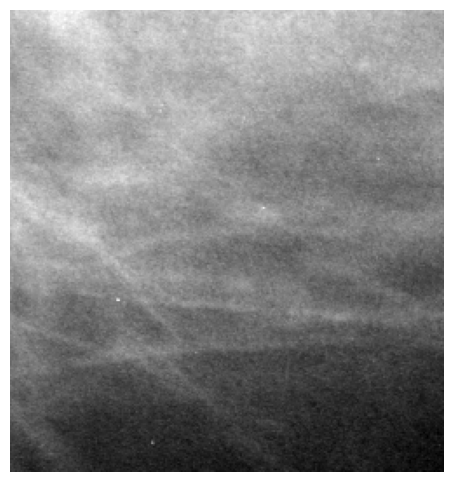

In [19]:
# Đọc thử một file DICOM thực tế

import pydicom
import matplotlib.pyplot as plt

cac_file_dicom = list(thu_muc_crop.glob("*.dcm"))
print("Số file DICOM trong thư mục mẫu:", len(cac_file_dicom))

if cac_file_dicom:
    file_mau = cac_file_dicom[0]
    dicom = pydicom.dcmread(file_mau)

    print("Tên file:", file_mau.name)
    print("Kích thước ảnh:", dicom.Rows, "x", dicom.Columns)

    anh = dicom.pixel_array
    print("Giải mã pixel thành công:", anh.shape)
    print("Kiểu dữ liệu:", anh.dtype)

    plt.figure(figsize=(6, 6))
    plt.imshow(anh, cmap="gray")
    plt.axis("off")
    plt.show()

In [20]:
# Xem thông tin mô tả của hai file DICOM mẫu

for file_dicom in cac_file_dicom:
    dicom = pydicom.dcmread(file_dicom)

    print(f"\nTên file: {file_dicom.name}")
    for ten_truong in [
        "Modality",
        "SeriesDescription",
        "StudyDescription",
        "Rows",
        "Columns",
        "PhotometricInterpretation",
        "SOPClassUID",
    ]:
        print(f"{ten_truong}: {getattr(dicom, ten_truong, 'Không có')}")


Tên file: 69e26641-50ca-4837-9e0e-1b9523b8848b.dcm
Modality: MG
SeriesDescription: cropped images
StudyDescription: Không có
Rows: 265
Columns: 249
PhotometricInterpretation: MONOCHROME2
SOPClassUID: 1.2.840.10008.5.1.4.1.1.7

Tên file: c959748f-9c7c-419b-8c9c-cb63bfe65e44.dcm
Modality: MG
SeriesDescription: Không có
StudyDescription: Không có
Rows: 4728
Columns: 3064
PhotometricInterpretation: MONOCHROME2
SOPClassUID: 1.2.840.10008.5.1.4.1.1.7


In [21]:
# Đối chiếu đường dẫn và thông tin hai file DICOM

for file_dicom in cac_file_dicom:
    dicom = pydicom.dcmread(file_dicom, stop_before_pixels=True)

    print(f"\nTên file: {file_dicom.name}")
    print("Đường dẫn tương đối:", file_dicom.relative_to(IMAGE_ROOT))
    print("Kích thước:", dicom.Rows, "x", dicom.Columns)

    for truong in [
        "SeriesDescription",
        "ImageType",
        "ViewPosition",
        "PatientID",
        "StudyInstanceUID",
        "SeriesInstanceUID",
        "SOPInstanceUID",
    ]:
        print(f"{truong}: {getattr(dicom, truong, 'Không có')}")


Tên file: 69e26641-50ca-4837-9e0e-1b9523b8848b.dcm
Đường dẫn tương đối: Calc-Test_P_00038_LEFT_MLO_1\2017-08-29-11739\1-cropped images-88680\69e26641-50ca-4837-9e0e-1b9523b8848b.dcm
Kích thước: 265 x 249
SeriesDescription: cropped images
ImageType: Không có
ViewPosition: Không có
PatientID: Calc-Test_P_00038_LEFT_MLO_1
StudyInstanceUID: 1.3.6.1.4.1.9590.100.1.2.29112199613143138535387754440942211739
SeriesInstanceUID: 1.3.6.1.4.1.9590.100.1.2.188613955710170417803011787532523988680
SOPInstanceUID: 1.3.6.1.4.1.9590.100.1.2.173338537212637308823544308673220823894

Tên file: c959748f-9c7c-419b-8c9c-cb63bfe65e44.dcm
Đường dẫn tương đối: Calc-Test_P_00038_LEFT_MLO_1\2017-08-29-11739\1-cropped images-88680\c959748f-9c7c-419b-8c9c-cb63bfe65e44.dcm
Kích thước: 4728 x 3064
SeriesDescription: Không có
ImageType: Không có
ViewPosition: Không có
PatientID: P_00038_LEFT_MLO_1.dcm
StudyInstanceUID: 1.3.6.1.4.1.9590.100.1.2.29112199613143138535387754440942211739
SeriesInstanceUID: 1.3.6.1.4.1.9590.1

In [22]:
# Khảo sát các mã bệnh nhân liên quan đến người tham gia P_00038

for ten, df in du_lieu_csv.items():
    cot = df["patient_id"].astype(str)
    mau = df[cot.str.contains("P_00038", case=False, na=False)]

    if not mau.empty:
        print(f"\n{ten}: {len(mau)} dòng")
        display(
            mau[[
                "patient_id",
                "left or right breast",
                "image view",
                "abnormality id",
                "abnormality type",
            ]].head(10)
        )


Vôi hóa - tập kiểm tra: 6 dòng


,patient_id,left or right breast,image view,abnormality id,abnormality type
0,P_00038,LEFT,CC,1,calcification
1,P_00038,LEFT,MLO,1,calcification
2,P_00038,RIGHT,CC,1,calcification
3,P_00038,RIGHT,CC,2,calcification
4,P_00038,RIGHT,MLO,1,calcification
5,P_00038,RIGHT,MLO,2,calcification


In [23]:
# Thống kê số mã bệnh nhân và số bản ghi trong từng CSV

bang_thong_ke = []

for ten, df in du_lieu_csv.items():
    bang_thong_ke.append({
        "Tệp CSV": ten,
        "Số bản ghi": len(df),
        "Số patient_id duy nhất": df["patient_id"].nunique(),
        "Số mã bất thường": df["abnormality id"].nunique(),
    })

display(pd.DataFrame(bang_thong_ke))

,Tệp CSV,Số bản ghi,Số patient_id duy nhất,Số mã bất thường
0,Vôi hóa - tập kiểm tra,326,151,5
1,Vôi hóa - tập huấn luyện,1546,602,7
2,Khối u - tập kiểm tra,378,201,4
3,Khối u - tập huấn luyện,1318,691,6


- Lưu ý: không cộng trực tiếp các số patient_id duy nhất giữa bốn CSV, vì cùng một mã có thể xuất hiện ở nhiều tệp. Tương tự, abnormality id chỉ là mã số được lặp lại theo từng trường hợp, không phải định danh tổn thương duy nhất trên toàn bộ dataset.

In [24]:
# Kiểm tra patient_id trùng giữa train và test

cac_cap = [
    ("Vôi hóa", "Vôi hóa - tập huấn luyện", "Vôi hóa - tập kiểm tra"),
    ("Khối u", "Khối u - tập huấn luyện", "Khối u - tập kiểm tra"),
]

for ten, ten_train, ten_test in cac_cap:
    ids_train = set(du_lieu_csv[ten_train]["patient_id"].dropna().astype(str))
    ids_test = set(du_lieu_csv[ten_test]["patient_id"].dropna().astype(str))
    trung = ids_train & ids_test

    print(f"\n{ten}")
    print("patient_id trong train:", len(ids_train))
    print("patient_id trong test:", len(ids_test))
    print("patient_id trùng giữa hai tập:", len(trung))
    if trung:
        print("Ví dụ mã trùng:", sorted(trung)[:10])


Vôi hóa
patient_id trong train: 602
patient_id trong test: 151
patient_id trùng giữa hai tập: 0

Khối u
patient_id trong train: 691
patient_id trong test: 201
patient_id trùng giữa hai tập: 0


- Diễn giải: theo trường patient_id trong CSV, hai tập đã tách biệt. Tuy nhiên, tài liệu tác giả cung cấp cảnh báo một người tham gia có thể mang nhiều mã bệnh nhân DICOM. Vì vậy, cần xác minh xem các mã khác nhau có cùng thuộc một người hay không.

In [25]:
# Khảo sát cấu trúc metadata DICOM

metadata = pd.read_csv(RAW_METADATA_FILE, low_memory=False)

print("Kích thước metadata:", metadata.shape)
print("\nTên các cột:")
for cot in metadata.columns:
    print("-", cot)

Kích thước metadata: (6775, 23)

Tên các cột:
- PatientID
- StudyInstanceUID
- StudyDate
- SeriesInstanceUID
- Collection
- Modality
- SeriesDescription
- BodyPartExamined
- SeriesNumber
- FileSize
- SOPClassUID
- sop_class_name
- TransferSyntaxUID
- transfer_syntax_name
- license_short_name
- aws_bucket
- crdc_series_uuid
- source_DOI
- DownloadURL
- S5cmdManifestPath
- OriginalS5cmdURI
- DownloadSource
- completion_status


In [26]:
# Thống kê định danh trong metadata gốc

cac_cot_id = [
    "PatientID",
    "StudyInstanceUID",
    "SeriesInstanceUID",
    "crdc_series_uuid",
]

for cot in cac_cot_id:
    print(
        f"{cot}: {metadata[cot].nunique(dropna=True):,} giá trị duy nhất; "
        f"{metadata[cot].isna().sum():,} giá trị thiếu"
    )

print("\nSố dòng metadata:", len(metadata))
print("Số PatientID duy nhất:", metadata["PatientID"].nunique())
print("Số StudyInstanceUID duy nhất:", metadata["StudyInstanceUID"].nunique())
print("Số SeriesInstanceUID duy nhất:", metadata["SeriesInstanceUID"].nunique())

PatientID: 6,671 giá trị duy nhất; 0 giá trị thiếu
StudyInstanceUID: 6,775 giá trị duy nhất; 0 giá trị thiếu
SeriesInstanceUID: 6,775 giá trị duy nhất; 0 giá trị thiếu
crdc_series_uuid: 6,775 giá trị duy nhất; 0 giá trị thiếu

Số dòng metadata: 6775
Số PatientID duy nhất: 6671
Số StudyInstanceUID duy nhất: 6775
Số SeriesInstanceUID duy nhất: 6775


- Mỗi dòng metadata có một StudyInstanceUID, SeriesInstanceUID và crdc_series_uuid duy nhất trong bảng này.


- Có 104 giá trị PatientID ít hơn số dòng metadata: \(6.775 - 6.671 = 104\). Điều này cho thấy có những PatientID được lặp lại.

In [27]:
# Tìm PatientID xuất hiện trong nhiều dòng metadata

so_lan = metadata["PatientID"].value_counts()
patient_id_lap = so_lan[so_lan > 1]

print("Số PatientID xuất hiện nhiều lần:", len(patient_id_lap))
print("Tổng số dòng thuộc các PatientID lặp:", int(patient_id_lap.sum()))

display(
    patient_id_lap.rename("Số dòng").reset_index()
    .rename(columns={"index": "PatientID"})
    .head(10)
)

Số PatientID xuất hiện nhiều lần: 104
Tổng số dòng thuộc các PatientID lặp: 208


,PatientID,Số dòng
0,Mass-Training_P_00841_RIGHT_CC_1,2
1,Mass-Training_P_00294_LEFT_CC_1,2
2,Mass-Training_P_00915_RIGHT_CC_1,2
3,Mass-Training_P_00384_RIGHT_CC_1,2
4,Mass-Training_P_01221_LEFT_CC_1,2
5,Mass-Training_P_00715_RIGHT_MLO_1,2
6,Mass-Training_P_01717_LEFT_CC_1,2
7,Mass-Test_P_00699_RIGHT_CC_1,2
8,Mass-Training_P_00694_RIGHT_CC_1,2
9,Mass-Training_P_01423_RIGHT_CC_1,2


- Vì 208 dòng thuộc 104 PatientID lặp, và mỗi ID trong bảng mẫu xuất hiện 2 lần, kết quả cho thấy 104 ID xuất hiện hai lần, tương ứng 104 dòng dư so với trường hợp mỗi ID chỉ xuất hiện một lần.

- Điều này chưa chứng minh có dữ liệu trùng ảnh hoặc trùng người tham gia. Một PatientID có thể liên kết với nhiều bản ghi Series khác nhau; cần xem các cột UID và thông tin ảnh để xác định ý nghĩa.

In [28]:
# Kiểm tra các bản ghi metadata có PatientID bị lặp

cot_can_xem = [
    "PatientID",
    "StudyInstanceUID",
    "SeriesInstanceUID",
    "SeriesDescription",
    "Collection",
    "crdc_series_uuid",
]

id_mau = patient_id_lap.index[:5]

display(
    metadata.loc[
        metadata["PatientID"].isin(id_mau),
        cot_can_xem
    ].sort_values("PatientID")
)

,PatientID,StudyInstanceUID,SeriesInstanceUID,SeriesDescription,Collection,crdc_series_uuid
71,Mass-Training_P_00294_LEFT_CC_1,1.3.6.1.4.1.9590.100.1.2.683731524131967007038...,1.3.6.1.4.1.9590.100.1.2.624776243139500736291...,ROI mask images,cbis_ddsm,8be418b6-c146-4c28-be07-e42b0d1e6b6b
5538,Mass-Training_P_00294_LEFT_CC_1,1.3.6.1.4.1.9590.100.1.2.655133039115427959267...,1.3.6.1.4.1.9590.100.1.2.219157189212113616029...,cropped images,cbis_ddsm,73c73192-1c83-47a9-8269-ac4fd6486c24
88,Mass-Training_P_00384_RIGHT_CC_1,1.3.6.1.4.1.9590.100.1.2.204825392210332001719...,1.3.6.1.4.1.9590.100.1.2.335810585126987620020...,ROI mask images,cbis_ddsm,3e28084d-dfc6-43b5-a2e1-e131209ca7f6
1199,Mass-Training_P_00384_RIGHT_CC_1,1.3.6.1.4.1.9590.100.1.2.410098276311573804136...,1.3.6.1.4.1.9590.100.1.2.352883294212333654901...,cropped images,cbis_ddsm,3d5f4a7f-5b02-42e4-b1da-82081c084585
9,Mass-Training_P_00841_RIGHT_CC_1,1.3.6.1.4.1.9590.100.1.2.222721762312445724234...,1.3.6.1.4.1.9590.100.1.2.321083824012327154626...,cropped images,cbis_ddsm,7399749b-e36e-44c1-9124-a2d06ab906a6
6689,Mass-Training_P_00841_RIGHT_CC_1,1.3.6.1.4.1.9590.100.1.2.181078373412362514205...,1.3.6.1.4.1.9590.100.1.2.372474890613185447528...,ROI mask images,cbis_ddsm,65377708-6c24-437f-a220-5914a1da8cba
72,Mass-Training_P_00915_RIGHT_CC_1,1.3.6.1.4.1.9590.100.1.2.640844312120078263081...,1.3.6.1.4.1.9590.100.1.2.581656545123349464168...,ROI mask images,cbis_ddsm,551add6e-05b8-45df-9565-8930eb43d088
378,Mass-Training_P_00915_RIGHT_CC_1,1.3.6.1.4.1.9590.100.1.2.524529684129450183197...,1.3.6.1.4.1.9590.100.1.2.399227192711656972900...,cropped images,cbis_ddsm,7be4ef6e-0872-4c57-9b2b-84c44aaacdd5
126,Mass-Training_P_01221_LEFT_CC_1,1.3.6.1.4.1.9590.100.1.2.316516973136467832394...,1.3.6.1.4.1.9590.100.1.2.182635244412450647337...,cropped images,cbis_ddsm,07e36ef4-b2ab-49f7-9b57-f007adf80420
1483,Mass-Training_P_01221_LEFT_CC_1,1.3.6.1.4.1.9590.100.1.2.323966223126632281056...,1.3.6.1.4.1.9590.100.1.2.115756551511607539711...,ROI mask images,cbis_ddsm,20ab214a-8932-4f93-9c80-86492703bc6a


- Một PatientID có thể xuất hiện ở hai Series với vai trò khác nhau, chẳng hạn cropped images và ROI mask images

- Hai dòng có StudyInstanceUID, SeriesInstanceUID và crdc_series_uuid khác nhau. Điều đó phù hợp với việc metadata mô tả hai Series khác nhau 

In [29]:
# Thống kê loại Series của các PatientID xuất hiện nhiều lần

metadata_lap = metadata[
    metadata["PatientID"].isin(patient_id_lap.index)
]

bang_loai_series = pd.crosstab(
    metadata_lap["PatientID"],
    metadata_lap["SeriesDescription"]
)

display(bang_loai_series.sum().to_frame("Số bản ghi"))
print("Số PatientID lặp:", metadata_lap["PatientID"].nunique())
print("\nCác loại Series xuất hiện:")
display(metadata_lap["SeriesDescription"].value_counts(dropna=False))

,Số bản ghi
SeriesDescription,
ROI mask images,104
cropped images,104


Số PatientID lặp: 104

Các loại Series xuất hiện:


SeriesDescription
cropped images     104
ROI mask images    104
Name: count, dtype: int64

- Đây là bằng chứng cho thấy trong nhóm 104 ID bị lặp, metadata có quy luật ghép cặp theo loại Series. Tuy nhiên, hai Series có cùng PatientID chưa đủ để khẳng định chúng chứa ảnh crop và mask tương ứng chính xác

In [30]:
# Thống kê toàn bộ loại Series trong metadata

print("Tổng số bản ghi:", len(metadata))
print("\nSố lượng theo loại Series:")

display(
    metadata["SeriesDescription"]
    .value_counts(dropna=False)
    .rename_axis("Loại Series")
    .to_frame("Số bản ghi")
)

Tổng số bản ghi: 6775

Số lượng theo loại Series:


,Số bản ghi
Loại Series,
full mammogram images,2857
cropped images,1991
ROI mask images,1681
NaN,246


- Full mammogram images: nhóm Series được mô tả là ảnh chụp nhũ ảnh toàn phần.

- Cropped images: nhóm Series được mô tả là ảnh crop.

- ROI mask images: nhóm Series được mô tả là ảnh mask vùng quan tâm.

- NaN: có 246 bản ghi không có SeriesDescription; chưa thể xác định vai trò chỉ dựa trên cột này.

In [31]:
# Kiểm tra các bản ghi thiếu SeriesDescription

metadata_thieu_mota = metadata[
    metadata["SeriesDescription"].isna()
]

print("Số bản ghi thiếu mô tả:", len(metadata_thieu_mota))
print(
    "Số PatientID duy nhất:",
    metadata_thieu_mota["PatientID"].nunique()
)

display(
    metadata_thieu_mota[
        [
            "PatientID",
            "StudyInstanceUID",
            "SeriesInstanceUID",
            "Modality",
            "BodyPartExamined",
            "SeriesNumber",
            "SOPClassUID",
        ]
    ].head(10)
)

Số bản ghi thiếu mô tả: 246
Số PatientID duy nhất: 246


,PatientID,StudyInstanceUID,SeriesInstanceUID,Modality,BodyPartExamined,SeriesNumber,SOPClassUID
5,P_01399_RIGHT_CC.dcm,1.3.6.1.4.1.9590.100.1.2.372642110712356188908...,1.3.6.1.4.1.9590.100.1.2.194993015913874932816...,MG,Right Breast,1,1.2.840.10008.5.1.4.1.1.7
21,P_01148_RIGHT_MLO.dcm,1.3.6.1.4.1.9590.100.1.2.143668172211077640031...,1.3.6.1.4.1.9590.100.1.2.482358696133886806393...,MG,Right Breast,1,1.2.840.10008.5.1.4.1.1.7
138,P_02420_RIGHT_MLO.dcm,1.3.6.1.4.1.9590.100.1.2.481136371126841602772...,1.3.6.1.4.1.9590.100.1.2.171130805912113865022...,MG,Right Breast,1,1.2.840.10008.5.1.4.1.1.7
232,P_01643_LEFT_MLO.dcm,1.3.6.1.4.1.9590.100.1.2.182366837111598032905...,1.3.6.1.4.1.9590.100.1.2.686057161262920973904...,MG,Left Breast,1,1.2.840.10008.5.1.4.1.1.7
260,P_00077_LEFT_CC.dcm,1.3.6.1.4.1.9590.100.1.2.171237778213286314004...,1.3.6.1.4.1.9590.100.1.2.120762895113344405411...,MG,Left Breast,1,1.2.840.10008.5.1.4.1.1.7
261,P_00127_RIGHT_MLO.dcm,1.3.6.1.4.1.9590.100.1.2.404823705712101112613...,1.3.6.1.4.1.9590.100.1.2.900667572137294102400...,MG,Right Breast,1,1.2.840.10008.5.1.4.1.1.7
334,P_00774_RIGHT_CC.dcm,1.3.6.1.4.1.9590.100.1.2.243980568812610421224...,1.3.6.1.4.1.9590.100.1.2.104540687813176285233...,MG,Right Breast,1,1.2.840.10008.5.1.4.1.1.7
366,P_01030_RIGHT_MLO.dcm,1.3.6.1.4.1.9590.100.1.2.125171114311395562424...,1.3.6.1.4.1.9590.100.1.2.228145110911907288720...,MG,Right Breast,1,1.2.840.10008.5.1.4.1.1.7
432,P_01425_LEFT_MLO.dcm,1.3.6.1.4.1.9590.100.1.2.165474704311136998913...,1.3.6.1.4.1.9590.100.1.2.369540432612826466101...,MG,Left Breast,1,1.2.840.10008.5.1.4.1.1.7
433,P_02418_RIGHT_MLO.dcm,1.3.6.1.4.1.9590.100.1.2.378112702011595265700...,1.3.6.1.4.1.9590.100.1.2.703383133124003982358...,MG,Right Breast,1,1.2.840.10008.5.1.4.1.1.7


- 246 bản ghi thiếu SeriesDescription có 246 PatientID khác nhau

In [32]:
# Kiểm tra DICOM của một số PatientID thiếu SeriesDescription

from pathlib import Path
import pydicom

for patient_id in metadata_thieu_mota["PatientID"].head(5):
    print(f"\nPatientID trong metadata: {patient_id}")

    ket_qua = metadata[
        metadata["PatientID"] == patient_id
    ].iloc[0]

    print("StudyInstanceUID:", ket_qua["StudyInstanceUID"])
    print("SeriesInstanceUID:", ket_qua["SeriesInstanceUID"])
    print("SeriesDescription:", ket_qua["SeriesDescription"])


PatientID trong metadata: P_01399_RIGHT_CC.dcm
StudyInstanceUID: 1.3.6.1.4.1.9590.100.1.2.372642110712356188908772712152810069535
SeriesInstanceUID: 1.3.6.1.4.1.9590.100.1.2.194993015913874932816965175272741424254
SeriesDescription: nan

PatientID trong metadata: P_01148_RIGHT_MLO.dcm
StudyInstanceUID: 1.3.6.1.4.1.9590.100.1.2.143668172211077640031848470364196848191
SeriesInstanceUID: 1.3.6.1.4.1.9590.100.1.2.48235869613388680639353952591204777460
SeriesDescription: nan

PatientID trong metadata: P_02420_RIGHT_MLO.dcm
StudyInstanceUID: 1.3.6.1.4.1.9590.100.1.2.4811363711268416027726795723158159993
SeriesInstanceUID: 1.3.6.1.4.1.9590.100.1.2.171130805912113865022755513943080674175
SeriesDescription: nan

PatientID trong metadata: P_01643_LEFT_MLO.dcm
StudyInstanceUID: 1.3.6.1.4.1.9590.100.1.2.182366837111598032905542780214046510285
SeriesInstanceUID: 1.3.6.1.4.1.9590.100.1.2.6860571612629209739046762663550661960
SeriesDescription: nan

PatientID trong metadata: P_00077_LEFT_CC.dcm
Stud

In [33]:
# Kiểm tra thư mục ảnh của 5 PatientID mẫu

for patient_id in metadata_thieu_mota["PatientID"].head(5):
    ten_thu_muc = Path(patient_id).stem

    print(f"\nPatientID: {patient_id}")
    print("Tên cần đối chiếu:", ten_thu_muc)

    thu_muc_khop = [
        p for p in IMAGE_ROOT.iterdir()
        if p.is_dir() and ten_thu_muc in p.name
    ]

    if thu_muc_khop:
        for p in thu_muc_khop[:5]:
            print("  Tìm thấy:", p.name)
    else:
        print("  Chưa tìm thấy thư mục khớp trực tiếp.")


PatientID: P_01399_RIGHT_CC.dcm
Tên cần đối chiếu: P_01399_RIGHT_CC
  Tìm thấy: Calc-Test_P_01399_RIGHT_CC_1
  Tìm thấy: P_01399_RIGHT_CC.dcm

PatientID: P_01148_RIGHT_MLO.dcm
Tên cần đối chiếu: P_01148_RIGHT_MLO
  Tìm thấy: Calc-Test_P_01148_RIGHT_MLO_1
  Tìm thấy: P_01148_RIGHT_MLO.dcm

PatientID: P_02420_RIGHT_MLO.dcm
Tên cần đối chiếu: P_02420_RIGHT_MLO
  Tìm thấy: Calc-Test_P_02420_RIGHT_MLO_1
  Tìm thấy: P_02420_RIGHT_MLO.dcm

PatientID: P_01643_LEFT_MLO.dcm
Tên cần đối chiếu: P_01643_LEFT_MLO
  Tìm thấy: P_01643_LEFT_MLO.dcm
  Tìm thấy: P_01643_LEFT_MLO_1.dcm

PatientID: P_00077_LEFT_CC.dcm
Tên cần đối chiếu: P_00077_LEFT_CC
  Tìm thấy: Calc-Test_P_00077_LEFT_CC_1
  Tìm thấy: P_00077_LEFT_CC.dcm


In [36]:
# Đối chiếu UID của 5 file DICOM mẫu với metadata

for patient_id in metadata_thieu_mota["PatientID"].head(5):
    duong_dan = IMAGE_ROOT / patient_id

    print(f"\nPatientID: {patient_id}")

    if not duong_dan.is_file():
        print("Không tìm thấy file tại:", duong_dan)
        continue

    ds = pydicom.dcmread(
        str(duong_dan),
        stop_before_pixels=True
    )

    print("Study UID khớp:",
          str(ds.get("StudyInstanceUID", "")) ==
          str(metadata.loc[
              metadata["PatientID"] == patient_id,
              "StudyInstanceUID"
          ].iloc[0]))

    print("Series UID khớp:",
          str(ds.get("SeriesInstanceUID", "")) ==
          str(metadata.loc[
              metadata["PatientID"] == patient_id,
              "SeriesInstanceUID"
          ].iloc[0]))


PatientID: P_01399_RIGHT_CC.dcm
Không tìm thấy file tại: C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_ddsm\P_01399_RIGHT_CC.dcm

PatientID: P_01148_RIGHT_MLO.dcm
Không tìm thấy file tại: C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_ddsm\P_01148_RIGHT_MLO.dcm

PatientID: P_02420_RIGHT_MLO.dcm
Không tìm thấy file tại: C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_ddsm\P_02420_RIGHT_MLO.dcm

PatientID: P_01643_LEFT_MLO.dcm
Không tìm thấy file tại: C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_ddsm\P_01643_LEFT_MLO.dcm

PatientID: P_00077_LEFT_CC.dcm
Không tìm thấy file tại: C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_ddsm\P_00077_LEFT_CC.dcm


In [37]:
# Xác minh đường dẫn thực tế bằng Python

duong_dan = IMAGE_ROOT / "P_01399_RIGHT_CC.dcm"

print("IMAGE_ROOT:", repr(str(IMAGE_ROOT)))
print("Đường dẫn đang kiểm tra:", repr(str(duong_dan)))
print("Đường dẫn tồn tại:", duong_dan.exists())
print("Là file:", duong_dan.is_file())
print("Là thư mục:", duong_dan.is_dir())

IMAGE_ROOT: 'C:\\Breast-Cancer-CBIS-DDSM\\Data\\rawdata\\cbis_ddsm'
Đường dẫn đang kiểm tra: 'C:\\Breast-Cancer-CBIS-DDSM\\Data\\rawdata\\cbis_ddsm\\P_01399_RIGHT_CC.dcm'
Đường dẫn tồn tại: True
Là file: False
Là thư mục: True


In [38]:
# Xem nội dung thư mục của một mẫu

duong_dan = IMAGE_ROOT / "P_01399_RIGHT_CC.dcm"

print("Thư mục:", duong_dan)

for p in list(duong_dan.iterdir())[:20]:
    print("[DIR]" if p.is_dir() else "[FILE]", p.name)

Thư mục: C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_ddsm\P_01399_RIGHT_CC.dcm
[DIR] 1-24254


In [39]:
# Kiểm tra thư mục con của mẫu P_01399_RIGHT_CC

thu_muc_mau = IMAGE_ROOT / "P_01399_RIGHT_CC.dcm"

for p in thu_muc_mau.iterdir():
    if p.is_dir():
        print(f"\n[THƯ MỤC] {p.name}")
        for tep in list(p.iterdir())[:10]:
            print(
                "  [DIR]" if tep.is_dir() else "  [FILE]",
                tep.name
            )
    else:
        print("[FILE]", p.name)


[THƯ MỤC] 1-24254
  [FILE] f759bc1a-92a5-4fb0-a84c-da32e226826c.dcm


In [40]:
# Đối chiếu UID của file DICOM thực tế

duong_dan_dicom = (
    IMAGE_ROOT
    / "P_01399_RIGHT_CC.dcm"
    / "1-24254"
    / "f759bc1a-92a5-4fb0-a84c-da32e226826c.dcm"
)

ds = pydicom.dcmread(
    str(duong_dan_dicom),
    stop_before_pixels=True
)

dong_metadata = metadata.loc[
    metadata["PatientID"] == "P_01399_RIGHT_CC.dcm"
].iloc[0]

print("File tồn tại:", duong_dan_dicom.is_file())
print("Study UID khớp:",
      str(ds.get("StudyInstanceUID", "")) ==
      str(dong_metadata["StudyInstanceUID"]))
print("Series UID khớp:",
      str(ds.get("SeriesInstanceUID", "")) ==
      str(dong_metadata["SeriesInstanceUID"]))

print("\nStudy UID trong DICOM:", ds.get("StudyInstanceUID"))
print("Series UID trong DICOM:", ds.get("SeriesInstanceUID"))

File tồn tại: True
Study UID khớp: True
Series UID khớp: True

Study UID trong DICOM: 1.3.6.1.4.1.9590.100.1.2.372642110712356188908772712152810069535
Series UID trong DICOM: 1.3.6.1.4.1.9590.100.1.2.194993015913874932816965175272741424254


In [41]:
# Kiểm tra UID DICOM của 5 mẫu thiếu SeriesDescription

from pathlib import Path
import pydicom

for patient_id in metadata_thieu_mota["PatientID"].head(5):
    thu_muc_mau = IMAGE_ROOT / patient_id

    dong = metadata.loc[
        metadata["PatientID"] == patient_id
    ].iloc[0]

    tep_dicom = list(thu_muc_mau.rglob("*.dcm"))

    print(f"\nPatientID: {patient_id}")
    print("Số file DICOM tìm thấy:", len(tep_dicom))

    if not tep_dicom:
        print("Chưa tìm thấy file DICOM.")
        continue

    for tep in tep_dicom:
        ds = pydicom.dcmread(
            str(tep),
            stop_before_pixels=True
        )

        study_khop = (
            str(ds.get("StudyInstanceUID", ""))
            == str(dong["StudyInstanceUID"])
        )
        series_khop = (
            str(ds.get("SeriesInstanceUID", ""))
            == str(dong["SeriesInstanceUID"])
        )

        print("File:", tep.name)
        print("  Study UID khớp:", study_khop)
        print("  Series UID khớp:", series_khop)


PatientID: P_01399_RIGHT_CC.dcm
Số file DICOM tìm thấy: 1
File: f759bc1a-92a5-4fb0-a84c-da32e226826c.dcm
  Study UID khớp: True
  Series UID khớp: True

PatientID: P_01148_RIGHT_MLO.dcm
Số file DICOM tìm thấy: 1
File: 098d6e0c-ff6f-4133-8f75-a09f2bd54e5b.dcm
  Study UID khớp: True
  Series UID khớp: True

PatientID: P_02420_RIGHT_MLO.dcm
Số file DICOM tìm thấy: 1
File: 4321cd05-b40d-424e-a876-e4c58a2e87bf.dcm
  Study UID khớp: True
  Series UID khớp: True

PatientID: P_01643_LEFT_MLO.dcm
Số file DICOM tìm thấy: 1
File: f4014859-7ede-40d3-8a63-9a0ca7dc1303.dcm
  Study UID khớp: True
  Series UID khớp: True

PatientID: P_00077_LEFT_CC.dcm
Số file DICOM tìm thấy: 1
File: 5cb69d31-aabb-49a9-a3d1-3656b297bfc1.dcm
  Study UID khớp: True
  Series UID khớp: True


In [42]:
# Đếm thư mục và file ngay dưới IMAGE_ROOT

muc_dau = list(IMAGE_ROOT.iterdir())

print("Tổng mục cấp đầu tiên:", len(muc_dau))
print("Số thư mục:", sum(p.is_dir() for p in muc_dau))
print("Số file:", sum(p.is_file() for p in muc_dau))

Tổng mục cấp đầu tiên: 6671
Số thư mục: 6671
Số file: 0


In [43]:
# Khảo sát cấu trúc một vài thư mục cấp đầu tiên

thu_muc_mau = [
    p for p in IMAGE_ROOT.iterdir()
    if p.is_dir()
][:5]

for thu_muc in thu_muc_mau:
    muc_con = list(thu_muc.iterdir())

    print(f"\nThư mục: {thu_muc.name}")
    print("Số mục con trực tiếp:", len(muc_con))

    for p in muc_con[:5]:
        loai = "Thư mục" if p.is_dir() else "File"
        print(f"  [{loai}] {p.name}")


Thư mục: Calc-Test_P_00038_LEFT_MLO_1
Số mục con trực tiếp: 1
  [Thư mục] 2017-08-29-11739

Thư mục: Calc-Test_P_00038_RIGHT_CC_1
Số mục con trực tiếp: 1
  [Thư mục] 2017-08-29-83105

Thư mục: Calc-Test_P_00038_RIGHT_MLO_2
Số mục con trực tiếp: 1
  [Thư mục] 2017-08-29-68463

Thư mục: Calc-Test_P_00077_LEFT_CC_1
Số mục con trực tiếp: 1
  [Thư mục] 2017-08-29-51179

Thư mục: Calc-Test_P_00077_LEFT_MLO_1
Số mục con trực tiếp: 1
  [Thư mục] 2017-08-29-30370


In [44]:
# Khảo sát tầng thư mục tiếp theo của một mẫu

thu_muc_mau = IMAGE_ROOT / "Calc-Test_P_00038_LEFT_MLO_1"

for thu_muc_ngay in thu_muc_mau.iterdir():
    if thu_muc_ngay.is_dir():
        print(f"Thư mục: {thu_muc_ngay.name}")

        muc_con = list(thu_muc_ngay.iterdir())
        print("Số mục con:", len(muc_con))

        for p in muc_con[:10]:
            loai = "Thư mục" if p.is_dir() else "File"
            print(f"  [{loai}] {p.name}")

Thư mục: 2017-08-29-11739
Số mục con: 1
  [Thư mục] 1-cropped images-88680


In [48]:
# Kiểm tra từng tầng thư mục của mẫu

thu_muc_mau = IMAGE_ROOT / "Calc-Test_P_00038_LEFT_MLO_1"

print("Thư mục mẫu tồn tại:", thu_muc_mau.exists())
print("Đường dẫn:", thu_muc_mau)

for cap_1 in thu_muc_mau.iterdir():
    print("\nTầng 1:", cap_1.name)
    print("  Là thư mục:", cap_1.is_dir())

    if cap_1.is_dir():
        for cap_2 in cap_1.iterdir():
            print("  Tầng 2:", cap_2.name)
            print("    Là thư mục:", cap_2.is_dir())

            if cap_2.is_dir():
                for cap_3 in cap_2.iterdir():
                    print("    Tầng 3:", cap_3.name)
                    print("      Là thư mục:", cap_3.is_dir())

Thư mục mẫu tồn tại: True
Đường dẫn: C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_ddsm\Calc-Test_P_00038_LEFT_MLO_1

Tầng 1: 2017-08-29-11739
  Là thư mục: True
  Tầng 2: 1-cropped images-88680
    Là thư mục: True
    Tầng 3: 69e26641-50ca-4837-9e0e-1b9523b8848b.dcm
      Là thư mục: False
    Tầng 3: c959748f-9c7c-419b-8c9c-cb63bfe65e44.dcm
      Là thư mục: False


In [49]:
# Đọc thông tin DICOM của mẫu và đối chiếu với metadata.csv

import pydicom

thu_muc_mau = IMAGE_ROOT / "Calc-Test_P_00038_LEFT_MLO_1"

for tep in thu_muc_mau.rglob("*.dcm"):
    ds = pydicom.dcmread(
        str(tep),
        stop_before_pixels=True
    )

    print(f"\nFile: {tep.name}")
    print("  PatientID:", ds.get("PatientID"))
    print("  StudyInstanceUID:", ds.get("StudyInstanceUID"))
    print("  SeriesInstanceUID:", ds.get("SeriesInstanceUID"))
    print("  SeriesDescription:", ds.get("SeriesDescription"))


File: 69e26641-50ca-4837-9e0e-1b9523b8848b.dcm
  PatientID: Calc-Test_P_00038_LEFT_MLO_1
  StudyInstanceUID: 1.3.6.1.4.1.9590.100.1.2.29112199613143138535387754440942211739
  SeriesInstanceUID: 1.3.6.1.4.1.9590.100.1.2.188613955710170417803011787532523988680
  SeriesDescription: cropped images

File: c959748f-9c7c-419b-8c9c-cb63bfe65e44.dcm
  PatientID: P_00038_LEFT_MLO_1.dcm
  StudyInstanceUID: 1.3.6.1.4.1.9590.100.1.2.29112199613143138535387754440942211739
  SeriesInstanceUID: 1.3.6.1.4.1.9590.100.1.2.188613955710170417803011787532523988680
  SeriesDescription: None


In [52]:
# LẬP CHỈ MỤC DICOM THEO SERIES UID

from pathlib import Path
from collections import defaultdict
from tqdm.auto import tqdm
import pydicom

# SeriesInstanceUID -> danh sách đường dẫn DICOM
dicom_theo_series = defaultdict(list)

tep_dicom = list(IMAGE_ROOT.rglob("*.dcm"))

print("Tổng số file .dcm tìm thấy:", len(tep_dicom))

for tep in tqdm(tep_dicom, desc="Đọc header DICOM"):
    try:
        ds = pydicom.dcmread(
            str(tep),
            stop_before_pixels=True,
            force=True
        )

        series_uid = ds.get("SeriesInstanceUID")

        if series_uid:
            dicom_theo_series[str(series_uid)].append(str(tep))

    except Exception:
        continue

print("\nSố SeriesInstanceUID duy nhất trong file DICOM:",
      len(dicom_theo_series))

Tổng số file .dcm tìm thấy: 10635


Đọc header DICOM:   0%|          | 0/10635 [00:00<?, ?it/s]


Số SeriesInstanceUID duy nhất trong file DICOM: 6775


In [53]:
# ĐỐI CHIẾU SERIES UID
# Mục tiêu: Kiểm tra mức độ khớp giữa metadata.csv và các file DICOM

series_metadata = set(
    metadata["SeriesInstanceUID"].dropna().astype(str)
)

series_dicom = set(dicom_theo_series.keys())

series_khop = series_metadata & series_dicom
series_thieu_trong_dicom = series_metadata - series_dicom
series_ngoai_metadata = series_dicom - series_metadata

print("=" * 65)
print("ĐỐI CHIẾU SERIES UID")
print("=" * 65)

print(f"Số Series trong metadata.csv: {len(series_metadata):,}")
print(f"Số Series tìm thấy trong DICOM: {len(series_dicom):,}")
print(f"Số Series khớp nhau: {len(series_khop):,}")
print(f"Số Series trong metadata nhưng không tìm thấy DICOM: "
      f"{len(series_thieu_trong_dicom):,}")
print(f"Số Series trong DICOM nhưng không có trong metadata: "
      f"{len(series_ngoai_metadata):,}")

print("\nSố file DICOM theo mỗi Series:")
print(f"Series chỉ có 1 file: "
      f"{sum(len(files) == 1 for files in dicom_theo_series.values()):,}")
print(f"Series có nhiều hơn 1 file: "
      f"{sum(len(files) > 1 for files in dicom_theo_series.values()):,}")

ĐỐI CHIẾU SERIES UID
Số Series trong metadata.csv: 6,775
Số Series tìm thấy trong DICOM: 6,775
Số Series khớp nhau: 6,775
Số Series trong metadata nhưng không tìm thấy DICOM: 0
Số Series trong DICOM nhưng không có trong metadata: 0

Số file DICOM theo mỗi Series:
Series chỉ có 1 file: 3,311
Series có nhiều hơn 1 file: 3,464


- Không có Series UID bị thiếu hoặc dư giữa metadata.csv và chỉ mục DICOM.

- Có 3.311 Series chứa một file DICOM và 3.464 Series chứa nhiều file DICOM.

- Sự khác nhau giữa số file DICOM và số Series là điều dữ liệu hiện tại thể hiện;

In [60]:
# KIỂM TRA KHẢ NĂNG ĐỌC HEADER DICOM
# Chỉ kiểm tra file thật, loại trừ thư mục có tên kết thúc bằng .dcm

tep_dicom_that = [
    tep for tep in IMAGE_ROOT.rglob("*.dcm")
    if tep.is_file()
]

so_doc_loi = 0
so_thieu_series_uid = 0
so_doc_duoc = 0

for tep in tqdm(tep_dicom_that, desc="Kiểm tra header DICOM"):
    try:
        ds = pydicom.dcmread(
            str(tep),
            stop_before_pixels=True,
            force=True
        )
        so_doc_duoc += 1

        if not ds.get("SeriesInstanceUID"):
            so_thieu_series_uid += 1

    except Exception:
        so_doc_loi += 1

print("=" * 60)
print("KẾT QUẢ KIỂM TRA HEADER DICOM")
print("=" * 60)
print(f"Tổng file DICOM thật: {len(tep_dicom_that):,}")
print(f"Đọc được header: {so_doc_duoc:,}")
print(f"Không đọc được header: {so_doc_loi:,}")
print(f"Thiếu SeriesInstanceUID: {so_thieu_series_uid:,}")

Kiểm tra header DICOM:   0%|          | 0/10239 [00:00<?, ?it/s]

KẾT QUẢ KIỂM TRA HEADER DICOM
Tổng file DICOM thật: 10,239
Đọc được header: 10,239
Không đọc được header: 0
Thiếu SeriesInstanceUID: 0


- Kết quả đối chiếu trước đó, cả 6.775/6.775 SeriesInstanceUID trong metadata.csv đều khớp với dữ liệu DICOM đã lập chỉ mục.

### Kết luận Notebook 01 — Data Inventory

Đã hoàn thành kiểm kê dữ liệu CBIS-DDSM và kiểm tra tính nhất quán ở mức metadata và DICOM header. Bốn CSV mô tả tổn thương gồm calcification/mass và train/test đã được kiểm tra; `metadata.csv` có 6.775 bản ghi Series. 

Toàn bộ 10.239 file DICOM thật đọc được header và có `SeriesInstanceUID`. Đồng thời, 6.775 Series UID trong metadata khớp với chỉ mục DICOM.

Kết quả cho thấy dữ liệu đủ điều kiện để chuyển sang bước khảo sát liên kết giữa metadata, CSV mô tả tổn thương và đường dẫn ảnh. Chưa kết luận về tính toàn vẹn của pixel ảnh hoặc độ chính xác của nhãn cho đến khi thực hiện các kiểm tra tương ứng.